# Name:-Amirul Ajijur Sheikh
Roll No:-50
Section:-C
Batch:-C4

In [66]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import (train_test_split,GridSearchCV,cross_val_score,StratifiedKFold)

from sklearn.neighbors import KNeighborsClassifier

from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix, precision_score, recall_score, f1_score)

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

In [67]:
#Step 1:Load dataset
df = pd.read_csv("diabetes.csv")

In [68]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [69]:
df.tail()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1
767,1,93,70,31,0,30.4,0.315,23,0


In [70]:
df.shape

(768, 9)

In [71]:
df.isnull()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...
763,False,False,False,False,False,False,False,False,False
764,False,False,False,False,False,False,False,False,False
765,False,False,False,False,False,False,False,False,False
766,False,False,False,False,False,False,False,False,False


In [72]:
df.columns

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='str')

In [73]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [74]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [75]:
df.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

In [76]:
df.duplicated().sum()

0

In [77]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## Univariate analysis

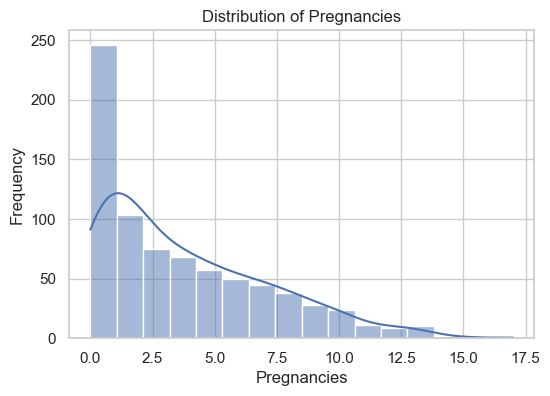

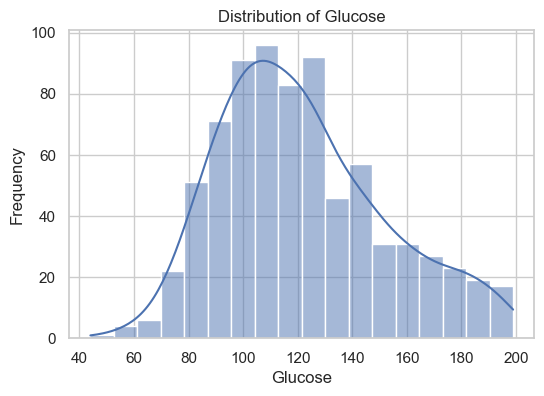

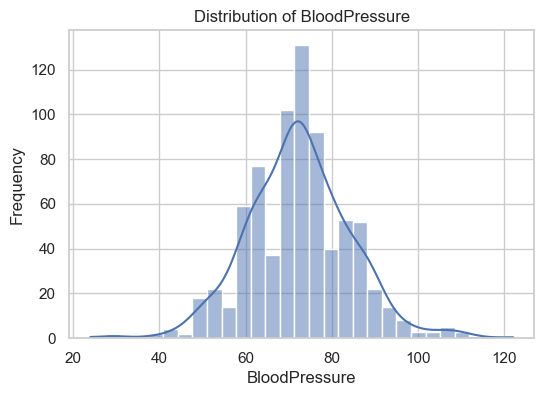

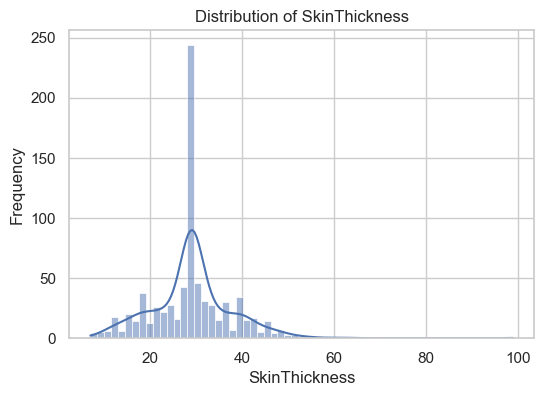

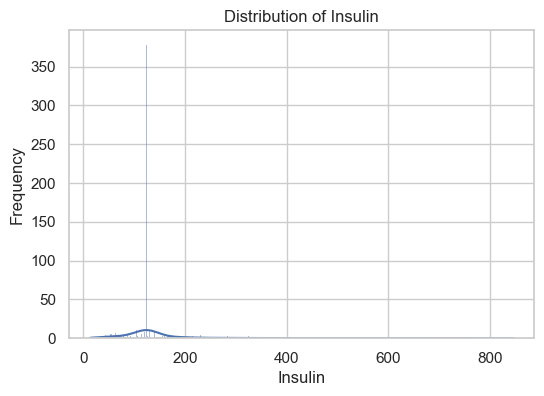

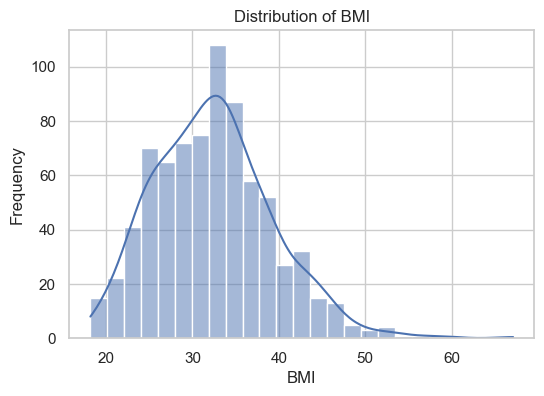

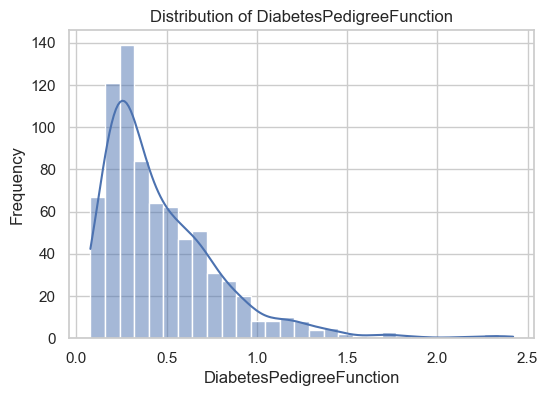

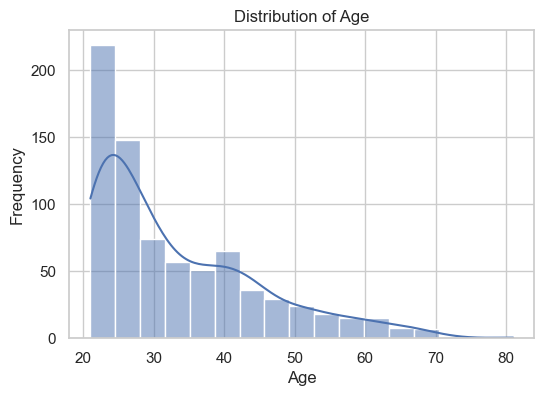

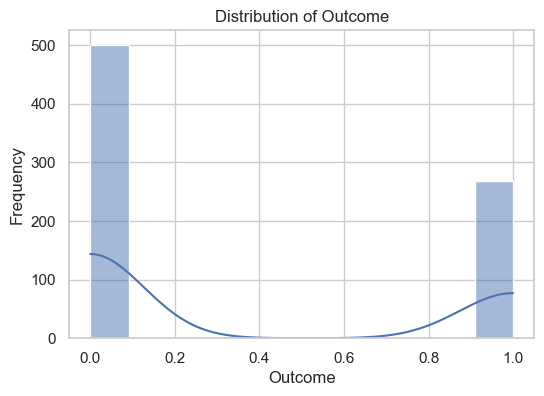

In [78]:
numeric_columns = df_clean.select_dtypes(include=np.number).columns

for col in numeric_columns:
    plt.figure(figsize=(6, 4))
    sns.histplot(df_clean[col], kde=True)
    plt.title("Distribution of " + col)
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()

## Box plot

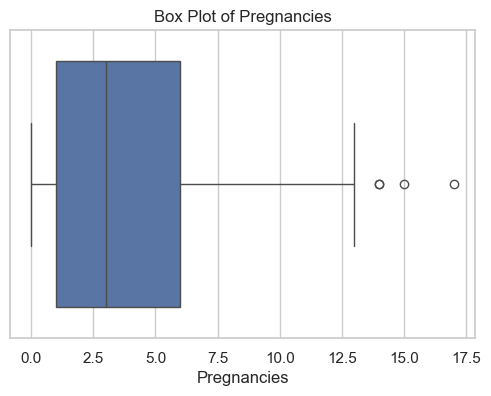

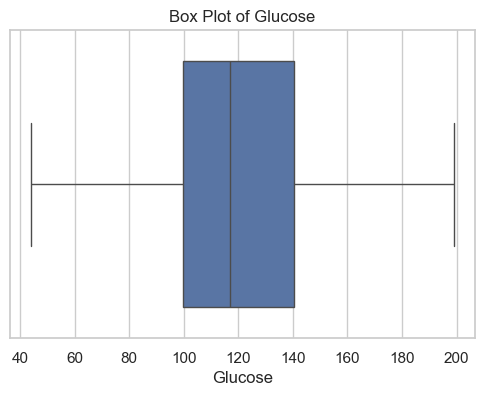

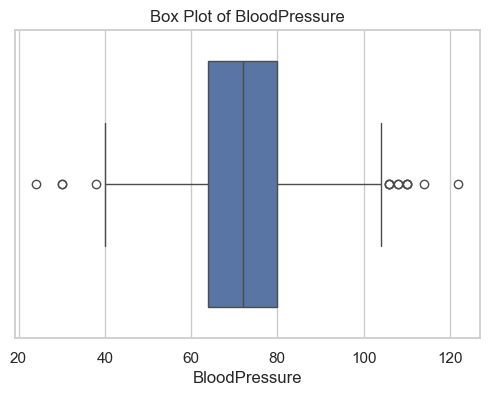

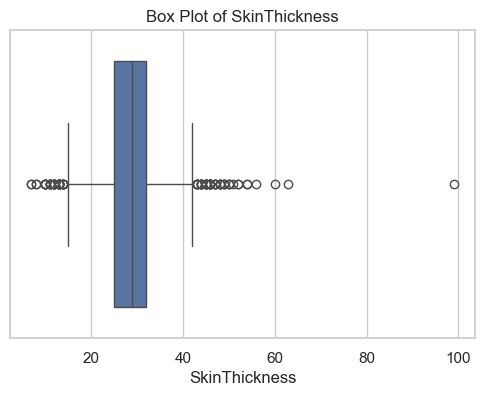

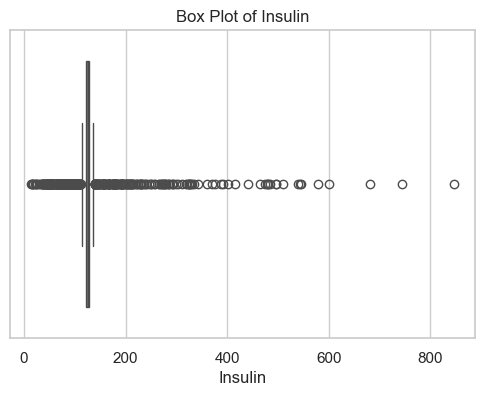

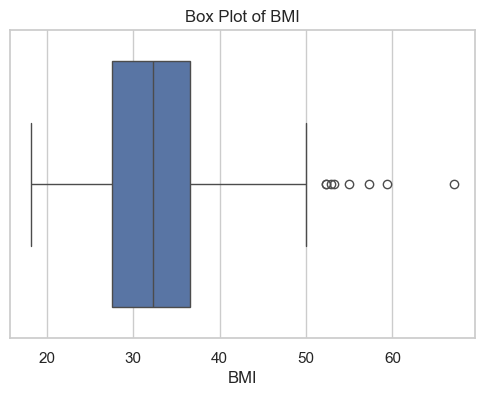

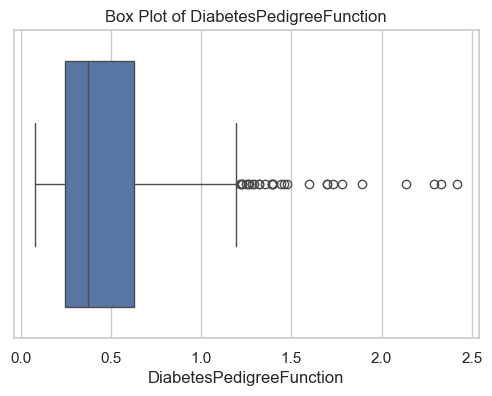

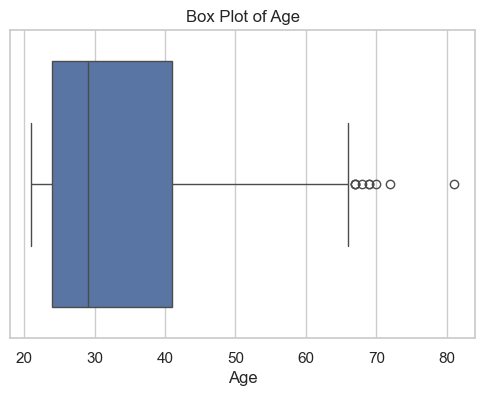

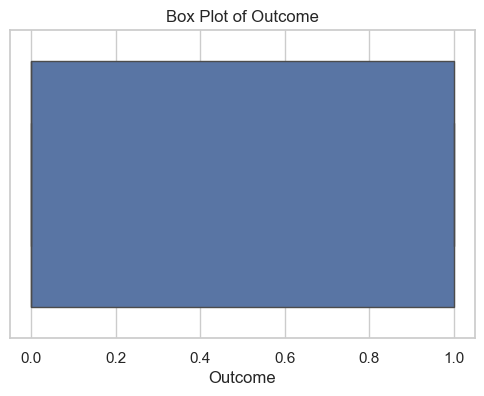

In [79]:
numeric_columns = df_clean.select_dtypes(include=np.number).columns

for col in numeric_columns:
    plt.figure(figsize=(6, 4))
    sns.boxplot(x=df_clean[col])
    plt.title("Box Plot of " + col)
    plt.xlabel(col)
    plt.show()

In [80]:
zero_columns = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
zero_counts = (df[zero_columns] == 0).sum()
print("Zero counts:",zero_counts)

Zero counts: Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


In [81]:
df_clean = df.copy()

df_clean[zero_columns] = df_clean[zero_columns].replace(0,np.nan)

print("Missing values after replacing invalid zeros:")
print(df_clean.isnull().sum())

Missing values after replacing invalid zeros:
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


In [82]:
for col in zero_columns:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())
print("Missing values after median imputation:")
print(df_clean.isnull().sum())

Missing values after median imputation:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


## Outliers

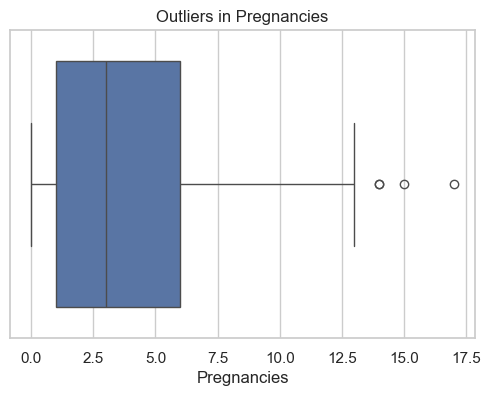

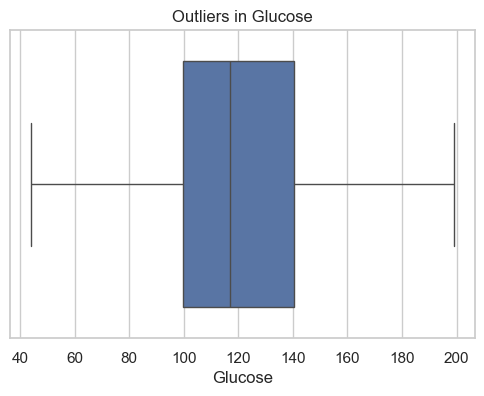

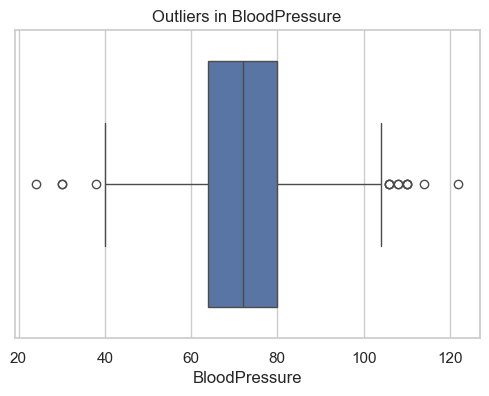

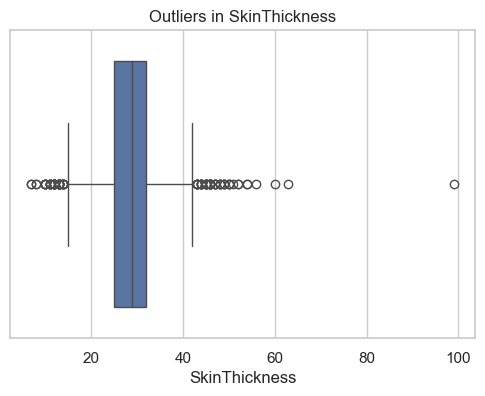

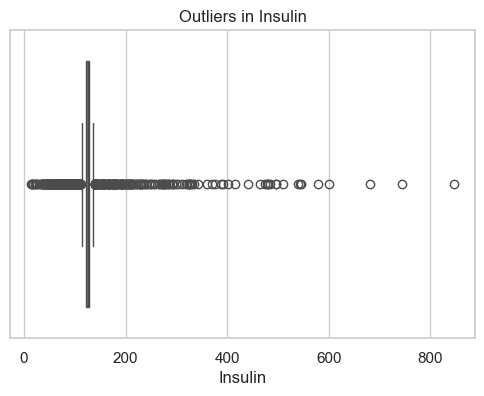

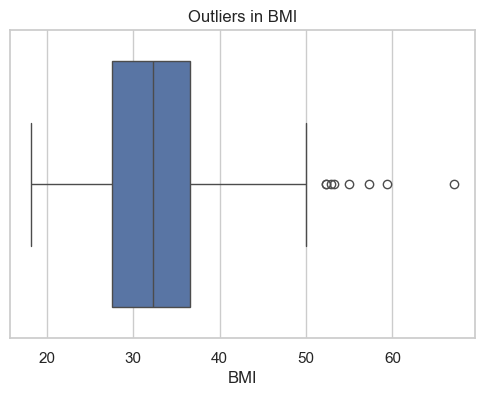

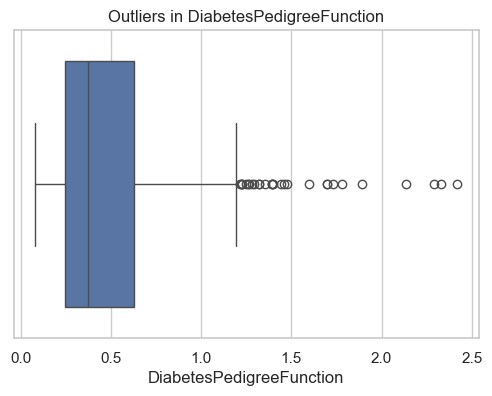

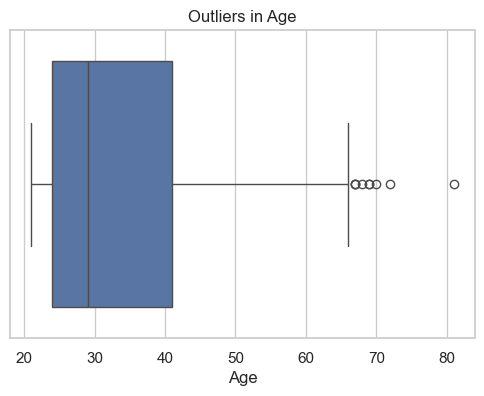

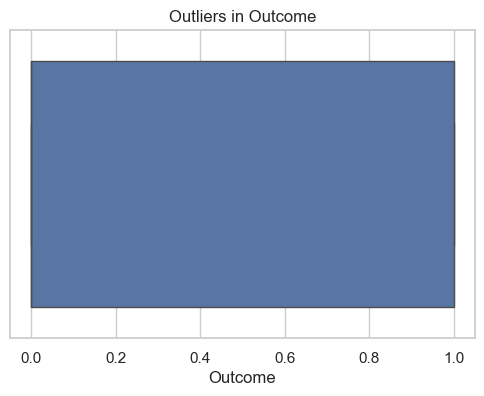

In [83]:
numeric_columns = df_clean.select_dtypes(include=np.number).columns

for col in numeric_columns:
    plt.figure(figsize=(6,4))
    sns.boxplot(x=df_clean[col])
    plt.title("Outliers in " + col)
    plt.show()

# IQR

In [84]:
Q1 = df_clean[numeric_columns].quantile(0.25)
Q3 = df_clean[numeric_columns].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = ((df_clean[numeric_columns] < lower_bound) |
            (df_clean[numeric_columns] > upper_bound))

print("Number of outliers in each column:")
print(outliers.sum())

Number of outliers in each column:
Pregnancies                   4
Glucose                       0
BloodPressure                14
SkinThickness                87
Insulin                     346
BMI                           8
DiabetesPedigreeFunction     29
Age                           9
Outcome                       0
dtype: int64


# Bi-variate analysis

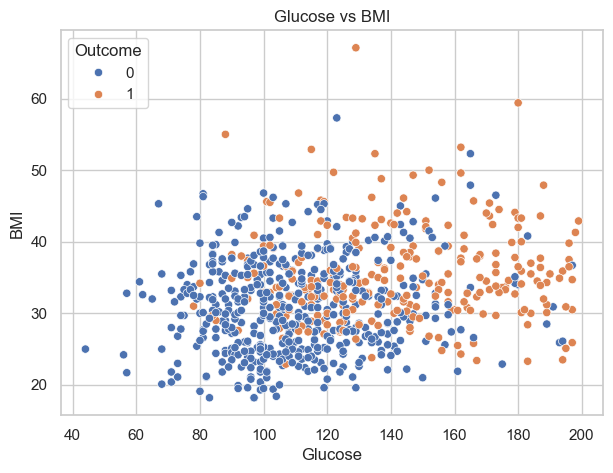

In [85]:
plt.figure(figsize=(7,5))
sns.scatterplot(data=df_clean, x="Glucose", y="BMI", hue="Outcome")
plt.title("Glucose vs BMI")
plt.show()

## Multivariate analysis

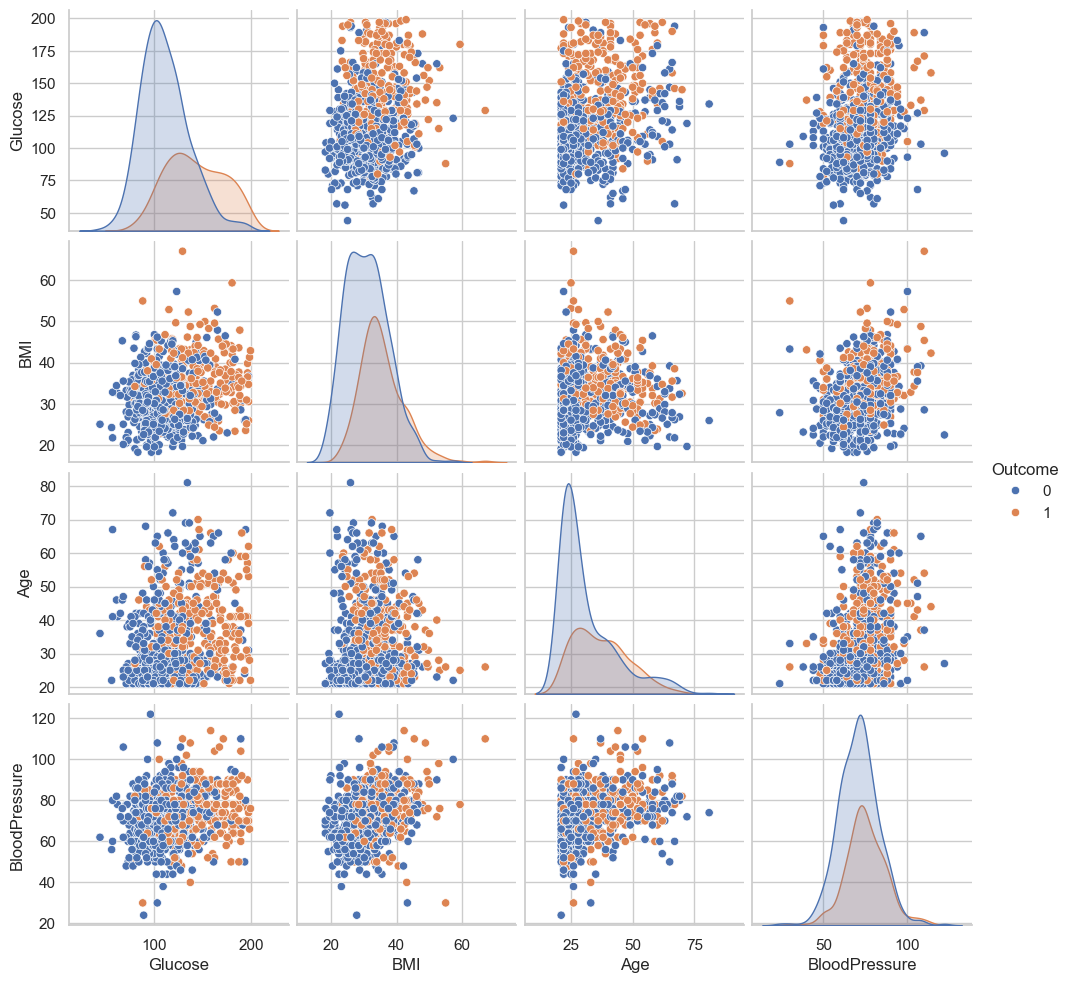

In [86]:
sns.pairplot(
    df_clean[["Glucose", "BMI", "Age", "BloodPressure", "Outcome"]],
    hue="Outcome"
)

plt.show()

## Heatmap

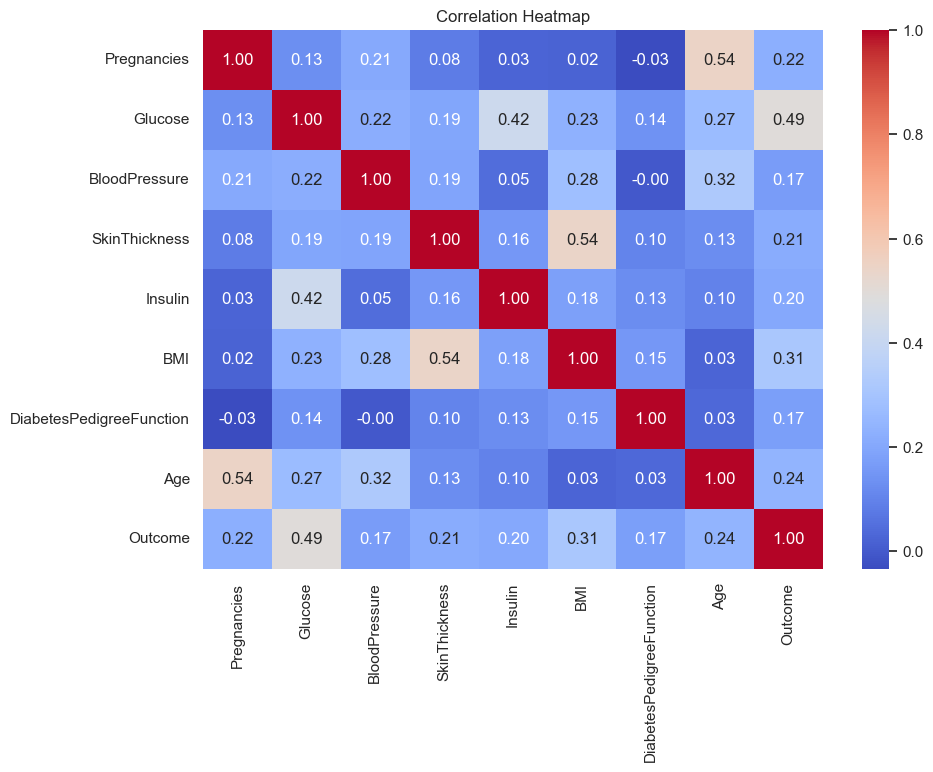

In [87]:
plt.figure(figsize=(10,7))

correlation = df_clean.corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

## Pair plot

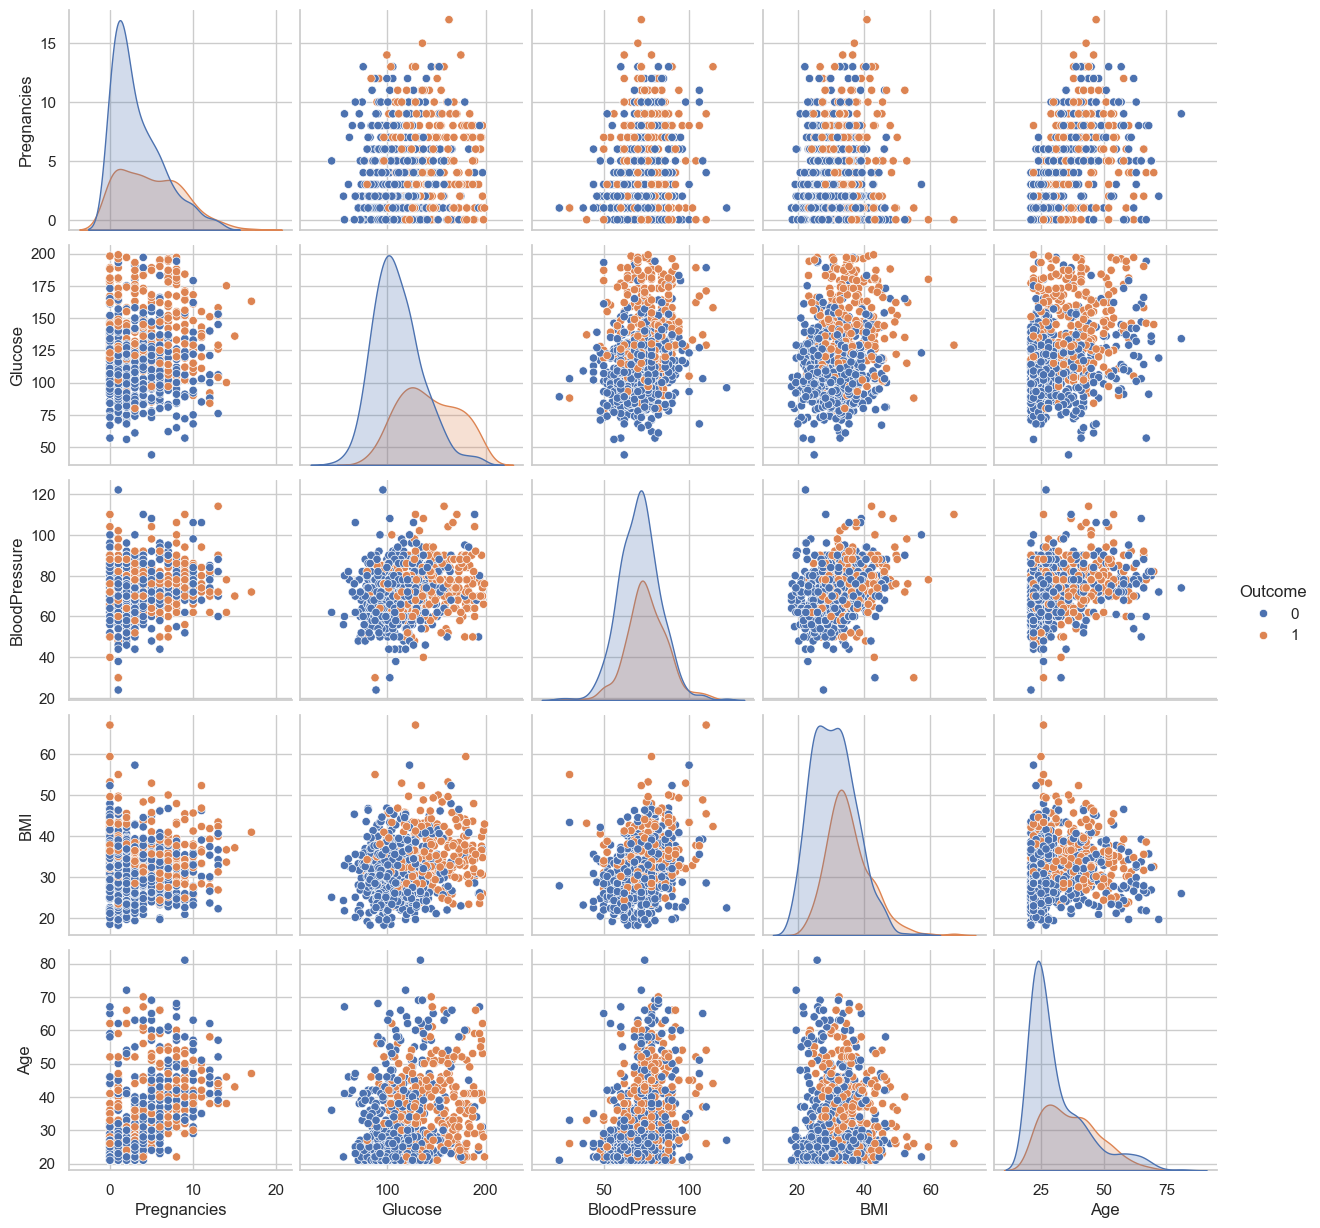

In [88]:
sns.pairplot(
    df_clean,
    vars=["Pregnancies", "Glucose", "BloodPressure", "BMI", "Age"],
    hue="Outcome"
)

plt.show()

## Apply KNN

In [89]:
X = df_clean.drop("Outcome", axis=1)
y = df_clean["Outcome"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Distribution:")
print(y_train.value_counts(normalize=True))
print("Testing Distribution:")
print(y_test.value_counts(normalize=True))

Training Distribution:
Outcome
0    0.651466
1    0.348534
Name: proportion, dtype: float64
Testing Distribution:
Outcome
0    0.649351
1    0.350649
Name: proportion, dtype: float64


In [90]:
# Feature scaling
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


In [91]:
X_train_original = X_train.copy()

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

comparison = pd.DataFrame({
    "Original Mean": X_train_original.mean(axis=0),
    "Original Std": X_train_original.std(axis=0),
    "Scaled Mean": X_train_scaled.mean(axis=0),
    "Scaled Std": X_train_scaled.std(axis=0)
}, index=X.columns)

display(comparison)

,Original Mean,Original Std,Scaled Mean,Scaled Std
Pregnancies,-6.576128e-17,1.0,0.000000e+00,1.0
Glucose,-5.948915e-17,1.0,-2.893089e-17,1.0
BloodPressure,3.139002e-16,1.0,1.446545e-17,1.0
SkinThickness,-2.115798e-16,1.0,-5.786179e-18,1.0
Insulin,-2.780643e-17,1.0,-4.339634e-18,1.0
BMI,-1.155880e-15,1.0,-1.735854e-17,1.0
DiabetesPedigreeFunction,-1.287425e-16,1.0,-1.735854e-17,1.0
Age,-9.230763e-17,1.0,-2.893089e-17,1.0


In [92]:
# Create KNN model
knn = KNeighborsClassifier(n_neighbors=5)

In [93]:
# Train model
knn.fit(X_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [94]:
y_pred = knn.predict(X_test)
print("Predictions:")
print(y_pred[:20])

Predictions:
[1 0 0 1 0 0 0 1 0 1 0 1 0 0 0 1 1 0 1 0]


In [95]:
y_prob = knn.predict_proba(X_test)[:, 1]
print(y_prob[:20])

[0.6 0.2 0.2 0.6 0.  0.2 0.2 0.8 0.  0.6 0.4 0.6 0.  0.  0.  0.6 0.8 0.
 1.  0.2]


In [96]:
# Accuracy
accuracy = accuracy_score(y_test, y_pred)
print("KNN Accuracy:", accuracy)

KNN Accuracy: 0.7532467532467533


In [97]:
# Precision
precision = precision_score(y_test, y_pred)
print(f"Precision: {precision:.4f}")

Precision: 0.6600


In [98]:
# Recall
recall = recall_score(y_test, y_pred)
print(f"Recall: {recall:.4f}")

Recall: 0.6111


In [99]:
# F1 score
f1 = f1_score(y_test, y_pred)
print(f"F1 score: {f1:.4f}")

F1 score: 0.6346


In [100]:
# Classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.83      0.81       100
           1       0.66      0.61      0.63        54

    accuracy                           0.75       154
   macro avg       0.73      0.72      0.72       154
weighted avg       0.75      0.75      0.75       154



In [101]:
# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)


Confusion Matrix:
[[83 17]
 [21 33]]


Confusion Matrix:
[[83 17]
 [21 33]]


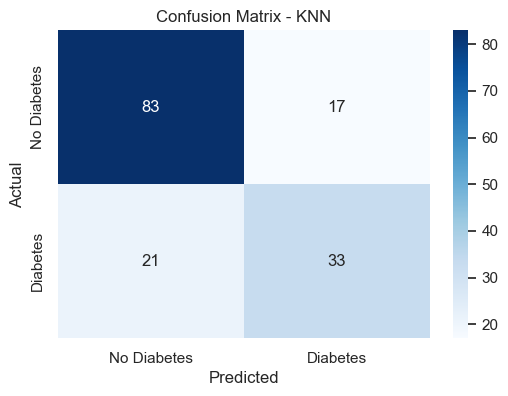

In [102]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Diabetes", "Diabetes"],
    yticklabels=["No Diabetes", "Diabetes"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - KNN")
plt.show()

In [108]:
k_values = range(1,31)

train_accuracy = []
test_accuracy = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_scaled, y_train)
    train_accuracy.append(model.score(X_train, y_train))
    test_accuracy.append(model.score(X_test, y_test))



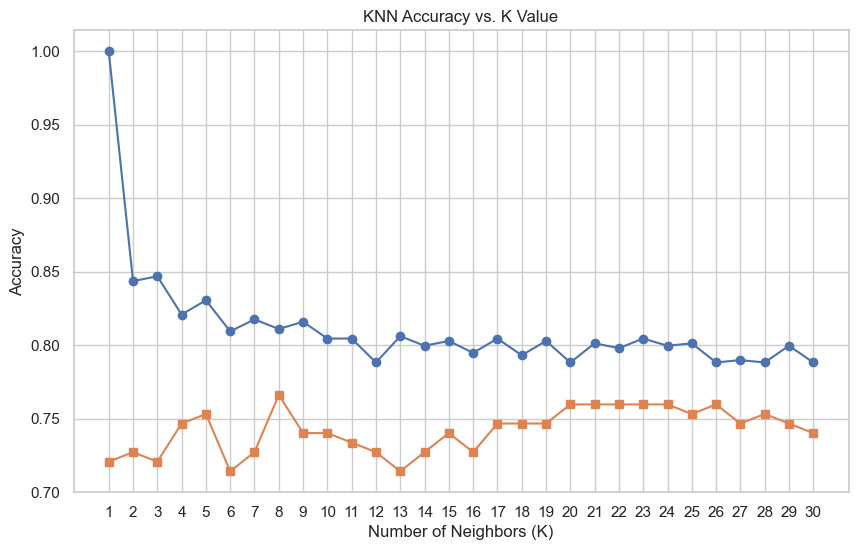

In [109]:
plt.figure(figsize=(10,6))
plt.plot(k_values, train_accuracy, marker = "o", label='Training Accuracy')
plt.plot(k_values, test_accuracy, marker = "s",label='Testing Accuracy')
plt.xlabel('Number of Neighbors (K)')
plt.ylabel('Accuracy')
plt.title('KNN Accuracy vs. K Value')
plt.xticks(k_values)
plt.show()

In [112]:
# Best K and Best Test Accuracy

best_k_accuracy = k_values[np.argmax(test_accuracy)]

best_accuracy = max(test_accuracy)



print("Best K:", best_k_accuracy)
print("Best Test Accuracy:", best_accuracy)

Best K: 8
Best Test Accuracy: 0.7662337662337663


In [115]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import Pipeline

# KNN model with scaling
knn_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=best_k_accuracy))
])

# 5-Fold Cross Validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    knn_pipeline,
    X,
    y,
    cv=cv,
    scoring="accuracy"
)

print("Cross Validation Scores:")
print(cv_scores)

print("\nMean Cross Validation Accuracy:",
      round(cv_scores.mean(), 4))

print("Mean Cross Validation Accuracy (%):",
      round(cv_scores.mean() * 100, 2), "%")

Cross Validation Scores:
[0.73376623 0.75974026 0.74025974 0.7254902  0.75163399]

Mean Cross Validation Accuracy: 0.7422
Mean Cross Validation Accuracy (%): 74.22 %


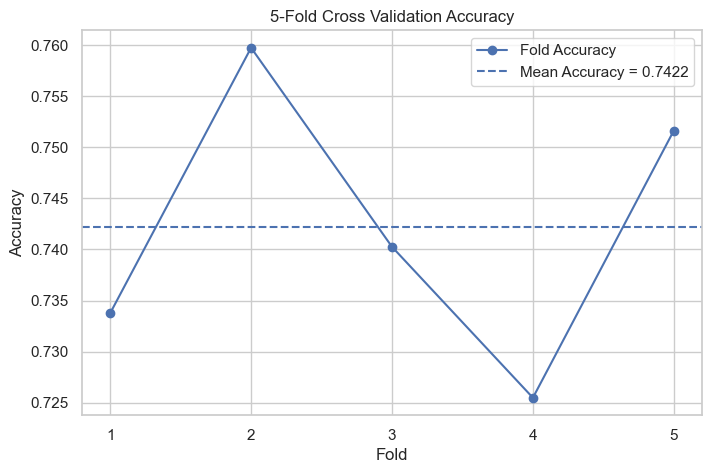

In [116]:
# Cross Validation Accuracy with Mean

mean_cv_accuracy = cv_scores.mean()

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(cv_scores) + 1),
    cv_scores,
    marker='o',
    label='Fold Accuracy'
)

plt.axhline(
    mean_cv_accuracy,
    linestyle='--',
    label=f'Mean Accuracy = {mean_cv_accuracy:.4f}'
)

plt.xlabel("Fold")
plt.ylabel("Accuracy")
plt.title("5-Fold Cross Validation Accuracy")

plt.xticks(range(1, len(cv_scores) + 1))
plt.legend()
plt.grid(True)

plt.show()

In [118]:
param_grid = {'n_neighbors': list(range(3,31,2)), "weights": ["uniform", "distance"],
              "metric": ["euclidean", "manhattan", "minkowski"],
              "p": [1,2]}

In [119]:
grid_search = GridSearchCV(estimator=KNeighborsClassifier(), param_grid=param_grid, cv=5, scoring='accuracy', n_jobs = -1)
grid_search.fit(X_train_scaled, y_train)
print("Grid Search Complete")

Grid Search Complete


In [120]:
print("Best parameters:")
print(grid_search.best_params_)
print("Best accuracy:")
print(grid_search.best_score_)

Best parameters:
{'metric': 'euclidean', 'n_neighbors': 19, 'p': 1, 'weights': 'uniform'}
Best accuracy:
0.7769025723044115
